# Unsupervised — Preprocessing (scaling dan transformasi kolom angka)
**Kapan dipakai:** sebelum clustering, PCA, KNN, SVM, atau model linear, yaitu model yang
peka terhadap besar kecilnya angka. Juga saat kolom sangat miring (banyak nilai kecil,
sedikit nilai sangat besar).

**Idenya:** tiap kolom diubah ke skala yang setara (misal rata-rata 0, simpangan 1) atau
bentuknya dibuat lebih simetris. Efeknya dicek lewat skewness, histogram, dan clustering.

**Langkah:**
1. Baca data, lihat rentang dan kemiringan tiap kolom.
2. Transformasi kolom.
3. Bandingkan hasil KMeans sebelum dan sesudah, simpan data hasil transformasi.

**Data demo:** Wine (13 kolom kimia, `proline` bernilai ratusan, kolom lain kecil).

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import MinMaxScaler, PowerTransformer, QuantileTransformer
from sklearn.preprocessing import RobustScaler, StandardScaler

## Konfigurasi

In [2]:
DATA_FOLDER = "../../data_latihan/unsupervised"   # GANTI saat lomba
DATA_CSV = f"{DATA_FOLDER}/wine.csv"

DROP_COLS = ["cultivar"]    # kolom yang tidak ditransformasi (label, id)
PLOT_COL = "proline"        # kolom yang digambar histogramnya
N_CLUSTERS = 3
SEED = 42

## Baca data

In [3]:
data = pd.read_csv(DATA_CSV)
X = data.drop(columns=DROP_COLS)
missing_per_column = X.isna().sum()
print(X.shape)
print("missing total:", missing_per_column.sum())
X.describe().round(2)

(178, 13)
missing total: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,13.00,2.34,2.37,19.49,99.74,2.30,2.03,0.36,1.59,5.06,0.96,2.61,746.89
std,0.81,1.12,0.27,3.34,14.28,0.63,1.00,0.12,0.57,2.32,0.23,0.71,314.91
min,11.03,0.74,1.36,10.60,70.00,0.98,0.34,0.13,0.41,1.28,0.48,1.27,278.00
25%,12.36,1.60,2.21,17.20,88.00,1.74,1.20,0.27,1.25,3.22,0.78,1.94,500.50
50%,13.05,1.87,2.36,19.50,98.00,2.36,2.13,0.34,1.56,4.69,0.96,2.78,673.50
75%,13.68,3.08,2.56,21.50,107.00,2.80,2.88,0.44,1.95,6.20,1.12,3.17,985.00
max,14.83,5.80,3.23,30.00,162.00,3.88,5.08,0.66,3.58,13.00,1.71,4.00,1680.00


## Langkah 2 — transformasi
Pilih SATU: hapus `#` di depan baris yang ingin dipakai, beri `#` pada baris lain.

                              skew_before  skew_after  min_after  max_after
alcohol                             -0.05       -0.05      -2.43       2.26
malic_acid                           1.04        1.04      -1.43       3.11
ash                                 -0.18       -0.18      -3.68       3.16
alcalinity_of_ash                    0.21        0.21      -2.67       3.15
magnesium                            1.10        1.10      -2.09       4.37
total_phenols                        0.09        0.09      -2.11       2.54
flavanoids                           0.03        0.03      -1.70       3.06
nonflavanoid_phenols                 0.45        0.45      -1.87       2.40
proanthocyanins                      0.52        0.52      -2.07       3.49
color_intensity                      0.87        0.87      -1.63       3.44
hue                                  0.02        0.02      -2.09       3.30
od280/od315_of_diluted_wines        -0.31       -0.31      -1.90       1.96
proline     

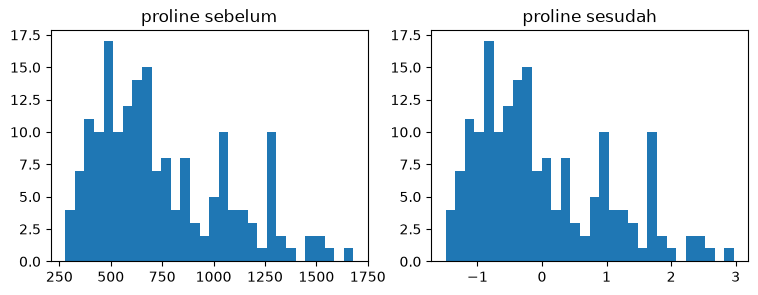

In [4]:
scaler = StandardScaler()                       # rata-rata 0, simpangan 1
# scaler = MinMaxScaler()                       # tiap kolom jadi 0..1
# scaler = RobustScaler()                       # pakai median, tahan nilai ekstrem
# scaler = PowerTransformer(method="yeo-johnson")   # kolom miring dibuat lebih simetris
# scaler = QuantileTransformer(output_distribution="normal", n_quantiles=100,
#                              random_state=SEED)   # paksa jadi bentuk lonceng

X_new = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

effect = pd.DataFrame()
effect["skew_before"] = X.skew()
effect["skew_after"] = X_new.skew()
effect["min_after"] = X_new.min()
effect["max_after"] = X_new.max()
print(effect.round(2))

fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].hist(X[PLOT_COL], bins=30)
axes[0].set_title(f"{PLOT_COL} sebelum")
axes[1].hist(X_new[PLOT_COL], bins=30)
axes[1].set_title(f"{PLOT_COL} sesudah")
plt.show()

## Langkah 3 — efek ke clustering
Silhouette tidak bisa dibandingkan langsung antar skala, jadi lihat juga ARI di sel terakhir.

In [5]:
kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=SEED)
labels_before = kmeans.fit_predict(X)
labels_after = kmeans.fit_predict(X_new)
print("silhouette sebelum:", round(silhouette_score(X, labels_before), 3))
print("silhouette sesudah:", round(silhouette_score(X_new, labels_after), 3))

silhouette sebelum: 0.571
silhouette sesudah: 0.285


## Simpan data hasil transformasi

In [6]:
submission = pd.DataFrame()
for name in X.columns:
    submission[name] = X_new[name]
for name in DROP_COLS:
    submission[name] = data[name]
submission.to_csv("submission.csv", index=False)
submission.head()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar
0,1.518613,-0.562250,0.232053,-1.169593,1.913905,0.808997,1.034819,-0.659563,1.224884,0.251717,0.362177,1.847920,1.013009,class_0
1,0.246290,-0.499413,-0.827996,-2.490847,0.018145,0.568648,0.733629,-0.820719,-0.544721,-0.293321,0.406051,1.113449,0.965242,class_0
2,0.196879,0.021231,1.109334,-0.268738,0.088358,0.808997,1.215533,-0.498407,2.135968,0.269020,0.318304,0.788587,1.395148,class_0
3,1.691550,-0.346811,0.487926,-0.809251,0.930918,2.491446,1.466525,-0.981875,1.032155,1.186068,-0.427544,1.184071,2.334574,class_0
4,0.295700,0.227694,1.840403,0.451946,1.281985,0.808997,0.663351,0.226796,0.401404,-0.319276,0.362177,0.449601,-0.037874,class_0


## Cek dengan kunci jawaban (HAPUS saat lomba)
ARI = kemiripan cluster dengan label asli (1 = sama persis, 0 = acak).

In [7]:
print("ARI sebelum:", round(adjusted_rand_score(data["cultivar"], labels_before), 3))
print("ARI sesudah:", round(adjusted_rand_score(data["cultivar"], labels_after), 3))

ARI sebelum: 0.371
ARI sesudah: 0.897
